In [25]:
import torch
import torch.nn  as nn
import timm
import numpy as np
import transformers
import matplotlib.pyplot as plt

import torchextractor as tx

#from tqdm import tqdm
from tqdm.notebook import tqdm #if using notebook

from torchvision import models
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

from torchmetrics.functional.pairwise import pairwise_cosine_similarity

from transformers import AutoProcessor,AutoModel
import sys
sys.path.append('/home/fxu/alignment/BLIP_Official')
from models.blip_itm import blip_itm

from datasets import load_dataset
from huggingface_hub import list_datasets

from convit_models import convit_base
from ConvNeXt import convnext_small

from torchvision.models.feature_extraction import get_graph_node_names,create_feature_extractor

In [2]:
def preprocess(examples):
    transform=transforms.Compose([
            transforms.Resize((224,224),antialias=True),
            transforms.ToTensor(),
            lambda img:torch.cat((img,img,img)) if img.size(0)==1 else img
            ])
    examples['image'] = [transform(img) for img in examples['image']]
    examples['label'] = [lbl for lbl in examples['label']]
    return examples

def string_label(idx):
    return imagenet1k_val.features['label'].names[idx]

def plot_images(images,labels):
    size=len(labels)
    fig,axes=plt.subplots(1,size,figsize=(size*3,3))
    for i in range(size):
        img=images[i].permute(1,2,0).numpy()
        label=string_label(labels[i]) if type(labels[i])==int else labels[i].item()
        axes[i].imshow(img)
        axes[i].set_title(label,fontsize=6)
        axes[i].axis('off')

In [3]:
imagenet1k_val = load_dataset('ILSVRC/imagenet-1k',split='validation',streaming=True,trust_remote_code=True)

batch_size=512
dataset_val = imagenet1k_val.map(preprocess, batched=True)
dataloader = DataLoader(dataset_val, batch_size=batch_size)

device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')

resnet34=models.resnet34(weights='ResNet34_Weights.DEFAULT')
convit=convit_base(pretrained=True)
convnext=convnext_small(pretrained=True,in_22k=False)

In [4]:
def compute_vision_acc(model,dataloader,device,eps=.0):
    model=model.to(device)
    total=0
    correct=0
    with torch.no_grad():
        for i,batch in tqdm(enumerate(dataloader)):
            images = (1-eps)*batch['image'].to(device)+eps*torch.rand(*batch['image'].size()).to(device)
            labels = batch['label'].to(device)
            model.eval()
            outputs=model(images)
            
            _,preds=torch.max(outputs.data,dim=1)
            correct+=(preds==labels).sum().item()
            total+=len(labels)
        acc=100*correct/total
        print(f'{model.__class__.__name__} accuracy with noise {eps}: {acc}')

In [5]:
def compute_multimodal_acc(model,dataloader,device,eps=0):
    model=model.to(device)
    text=[f"a picture of {name.strip().split(',')[0]}" for name in imagenet1k_val.features['label'].names]
    with torch.no_grad():
        if model.__class__.__name__=='BLIP_ITM':
            _,caption_features=model(image=torch.zeros(1,3,224,224).to(device),caption=text,match_head='itc')
        elif model.__class__.__name__=='CLIPModel':
            processor=AutoProcessor.from_pretrained("openai/clip-vit-base-patch32")
            caption_inputs=processor(text=text,return_tensors='pt',padding=True,truncation=True).to(device)
            caption_features=model.get_text_features(**caption_inputs).detach()
        else:
            raise Exception('No such a model.')
        total=0
        correct=0
        for i,batch in tqdm(enumerate(dataloader)):
            images=(1-eps)*batch['image'].to(device)+eps*torch.rand(*batch['image'].size()).to(device)
            labels=batch['label'].to(device)
            if model.__class__.__name__=='BLIP_ITM':
                img_features,_=model(image=images,caption=[''],match_head='itc')
            elif model.__class__.__name__=='CLIPModel':
                img_inputs=processor(images=images,return_tensors='pt',do_rescale=False).to(device)
                img_features=model.get_image_features(**img_inputs).detach()
                
            cosine=pairwise_cosine_similarity(img_features,caption_features)
            _,preds=torch.max(cosine,dim=1)
            correct+=(preds==labels).sum().item()
            total+=len(labels)
        acc=100*correct/total
        print(f'{model.__class__.__name__} accuracy with noise {eps}: {acc}')

In [6]:
clip=AutoModel.from_pretrained('openai/clip-vit-base-patch32')
clip=clip.to(device)
clip_processor=AutoProcessor.from_pretrained("openai/clip-vit-base-patch32")

In [7]:
model_url = 'https://storage.googleapis.com/sfr-vision-language-research/BLIP/models/model_base_retrieval_coco.pth'
model = blip_itm(pretrained=model_url, image_size=224, vit='base').eval()

reshape position embedding from 576 to 196
load checkpoint from https://storage.googleapis.com/sfr-vision-language-research/BLIP/models/model_base_retrieval_coco.pth


In [99]:
torch.manual_seed(110)
idx=torch.randint(1,1000,(1,))
for i,data in enumerate(dataset_val):
    if i==idx:
        img=data['image']
        label=data['label']
    elif i>idx:
        break

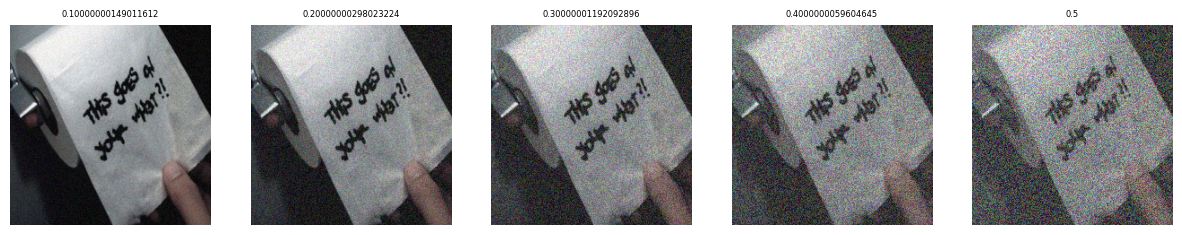

In [100]:
corrupted_imgs=[]
for noise in torch.arange(0.1,0.55,0.1):
    corrupted_imgs.append((1-noise)*img+noise*torch.rand(*img.size()))
plot_images(corrupted_imgs,torch.arange(0.1,0.55,0.1))

In [101]:
clip_inputs=clip_processor(images=[img]+corrupted_imgs,return_tensors='pt',do_rescale=False).to(device)
clip_vit_features=clip.get_image_features(**clip_inputs).detach()

In [102]:
clip_cosine=pairwise_cosine_similarity(clip_vit_features,clip_vit_features)
print(clip_cosine[0,1:])

tensor([0.9508, 0.9107, 0.8266, 0.8135, 0.7992], device='cuda:0')


In [103]:
def plot_feat(feats,titles):
    fig,axes=plt.subplots(1,5,figsize=(15,3),sharex=True,sharey=True)
    for i in range(5):
        feat=feats[i].reshape(32,-1).numpy()
        ax=axes[i]
        im=ax.imshow(feat,cmap='viridis',interpolation='nearest')
        ax.axis('off')
        cbar=plt.colorbar(im,ax=ax,fraction=0.06,pad=0.02)
        cbar.ax.tick_params(rotation=55)
        ax.set_title(round(titles[i].item(),2))

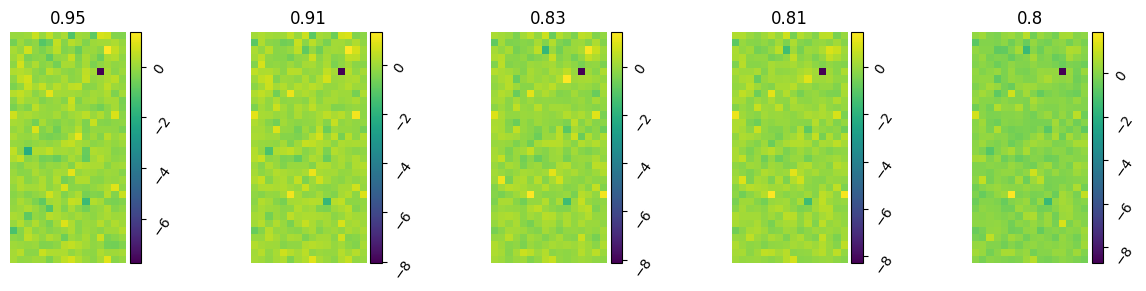

In [104]:
plot_feat(clip_vit_features.cpu()[1:],clip_cosine[0,1:])

In [120]:
with torch.no_grad():
    blip_features,_=model(image=torch.cat([img.unsqueeze(0) for img in [img]+corrupted_imgs],dim=0),caption=[''],match_head='itc')
blip_cosine=pairwise_cosine_similarity(blip_features,blip_features)

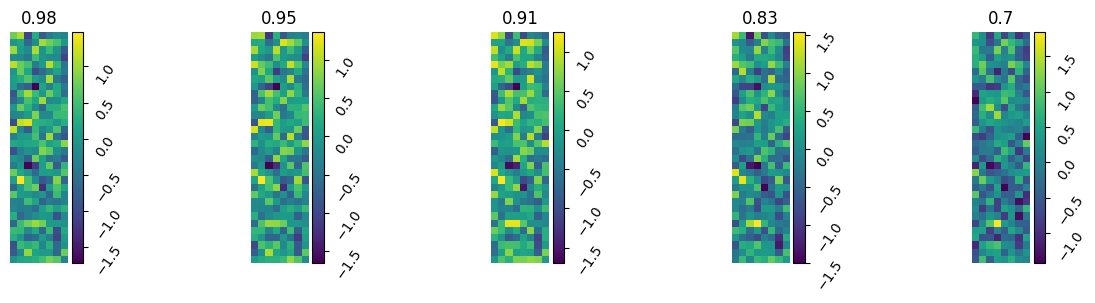

In [121]:
plot_feat(blip_features[1:],blip_cosine[0,1:])

In [105]:
nodes,_=get_graph_node_names(resnet34,suppress_diff_warning=True)
resnet_extractor=create_feature_extractor(resnet34,return_nodes=[nodes[-2]])

In [106]:
resnet_features=resnet_extractor(torch.cat([img.unsqueeze(0) for img in [img]+corrupted_imgs],dim=0))[nodes[-2]].detach()
resnet_cosine=pairwise_cosine_similarity(resnet_features,resnet_features)

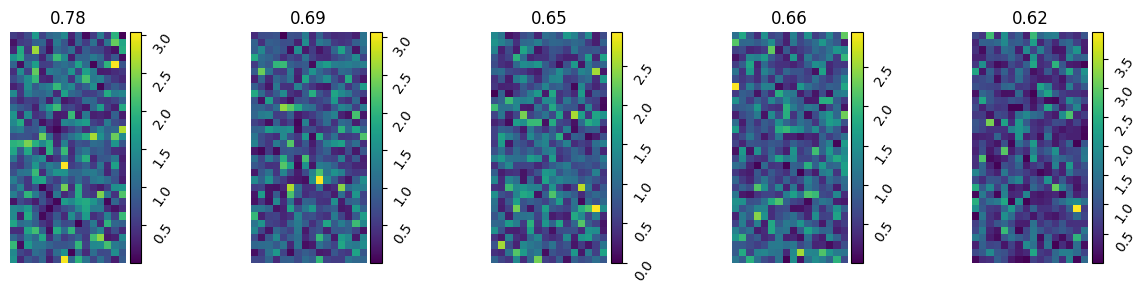

In [107]:
plot_feat(resnet_features[1:],resnet_cosine[0,1:])

In [108]:
small_nodes,_=get_graph_node_names(convnext,suppress_diff_warning=True)
convnext_extractor=create_feature_extractor(convnext,return_nodes=[small_nodes[-2]])

In [109]:
convnext_features=convnext_extractor(torch.cat([img.unsqueeze(0) for img in [img]+corrupted_imgs],dim=0))[small_nodes[-2]].detach()
convnext_cosine=pairwise_cosine_similarity(convnext_features,convnext_features)

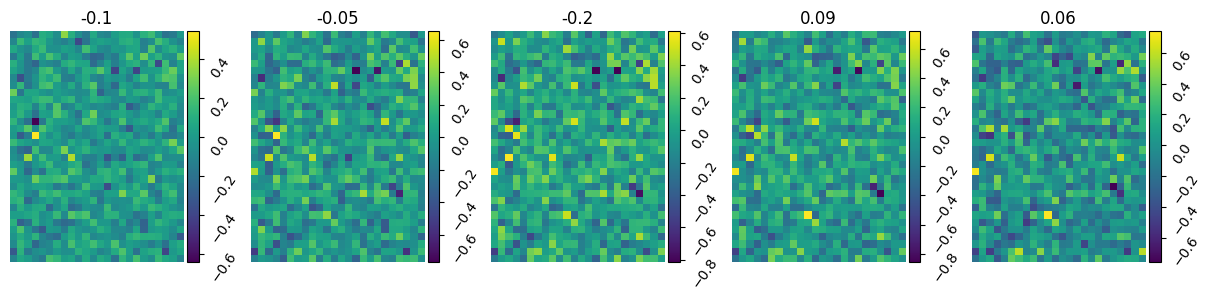

In [110]:
plot_feat(convnext_features,convnext_features[0,1:])

In [111]:
convit_extractor=tx.Extractor(convit,['norm'])

In [112]:
_,convit_features=convit_extractor(torch.cat([img.unsqueeze(0) for img in [img]+corrupted_imgs],dim=0))
convit_features=torch.mean(convit_features['norm'].detach(),dim=1)
convit_cosine=pairwise_cosine_similarity(convit_features,convit_features)

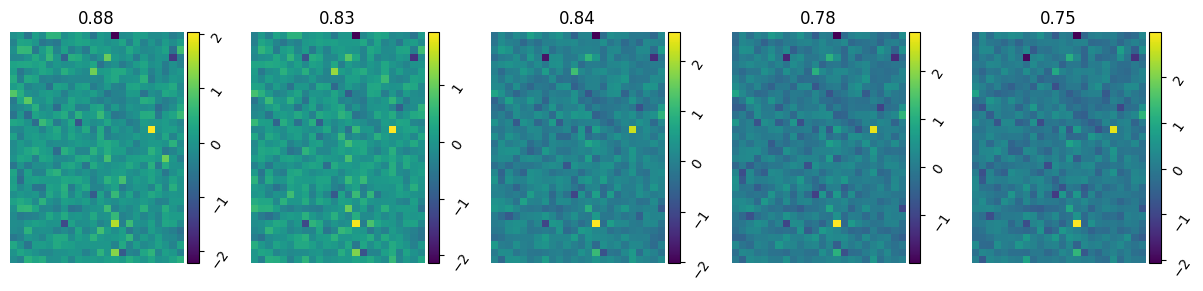

In [113]:
plot_feat(convit_features,convit_cosine[0,1:])

# Clustering based on img2img cosine similarity.

#### pending